# Team efficiency: offensive vs. defensive EPA/play

**EPA (expected points added)** measures how much each play changed a team's expected points. Averaging it per play is the best single measure of how efficient an offense or defense is.

We drop *garbage time* (win probability outside 10–90%) because teams play differently once a game is decided.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from nfl_analytics import load_pbp, offensive_plays
pd.set_option("display.precision", 3)

SEASON = 2026  # change to 2025 to look back at the final season

In [2]:
pbp = load_pbp(SEASON)
plays = offensive_plays(pbp)  # pass + run plays, regular season, WP 10-90%
weeks = int(plays["week"].max())
through = "regular season" if weeks >= 18 else f"through week {weeks}"
print(f"{len(pbp):,} total plays -> {len(plays):,} analyzed plays ({through})")

18,738 total plays -> 11,170 analyzed plays (through week 7)


## Team EPA table
For defense, **lower** EPA allowed is better. `net_epa` = offense minus defense.

In [3]:
from nfl_analytics import team_epa

teams = team_epa(plays)
teams

,off_plays,off_epa,off_success,off_pass_rate,def_plays,def_epa,def_success,net_epa
team,,,,,,,,
SF,326,0.147,0.540,0.592,351,-0.061,0.422,0.208
CIN,278,0.141,0.500,0.709,300,-0.037,0.427,0.178
CHI,384,0.112,0.484,0.583,264,-0.053,0.409,0.165
KC,298,0.161,0.480,0.607,316,0.003,0.408,0.159
BAL,349,0.128,0.467,0.582,367,0.014,0.444,0.114
LA,396,0.085,0.482,0.669,368,-0.019,0.443,0.104
JAX,310,0.085,0.461,0.610,297,-0.018,0.414,0.103
BUF,329,0.193,0.480,0.593,373,0.097,0.485,0.095
MIN,348,-0.097,0.371,0.595,329,-0.191,0.334,0.094


## The chart
The y-axis is inverted so **up and to the right is good** on both sides of the ball.

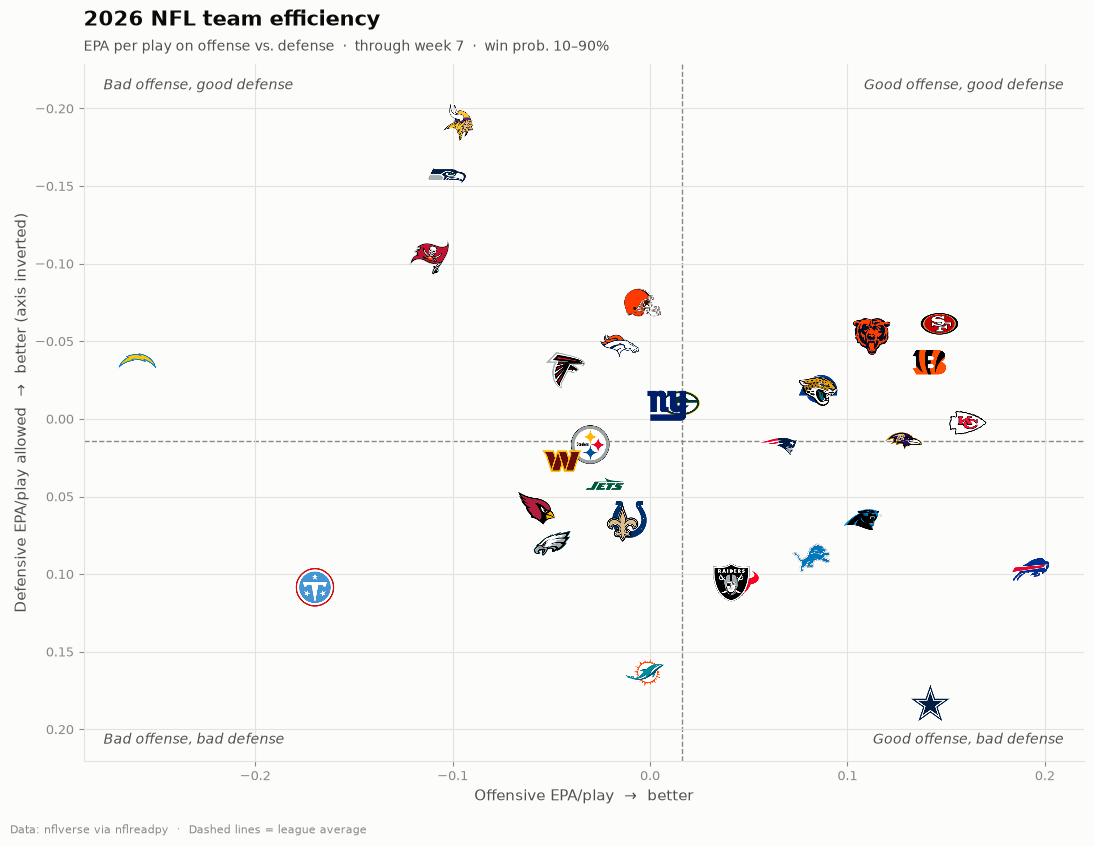

In [4]:
from nfl_analytics import plot_team_efficiency

fig, ax = plot_team_efficiency(
    teams,
    title=f"{SEASON} NFL team efficiency",
    subtitle=f"EPA per play on offense vs. defense  ·  {through}  ·  win prob. 10–90%",
)

## Passing vs. rushing efficiency
Split each offense into **dropbacks** (passes, sacks and scrambles) and **designed runs**. Both axes share a scale, so you can see that passing efficiency varies far more between teams than rushing does. Teams above the diagonal ran more efficiently than they passed.

In [5]:
from nfl_analytics import team_pass_rush_epa, plot_pass_vs_rush

split = team_pass_rush_epa(plays)
split

,pass_epa,rush_epa,pass_plays,rush_plays,pass_rate,pass_minus_rush
team,,,,,,
BUF,0.329,-0.005,195,134,0.593,0.334
BAL,0.269,-0.067,203,146,0.582,0.336
CHI,0.262,-0.097,224,160,0.583,0.359
CIN,0.238,-0.093,197,81,0.709,0.331
SF,0.234,0.019,193,133,0.592,0.215
DET,0.227,-0.119,166,121,0.578,0.346
NE,0.216,-0.175,214,135,0.613,0.391
DAL,0.202,0.035,231,129,0.642,0.167
LV,0.192,-0.206,219,133,0.622,0.398


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


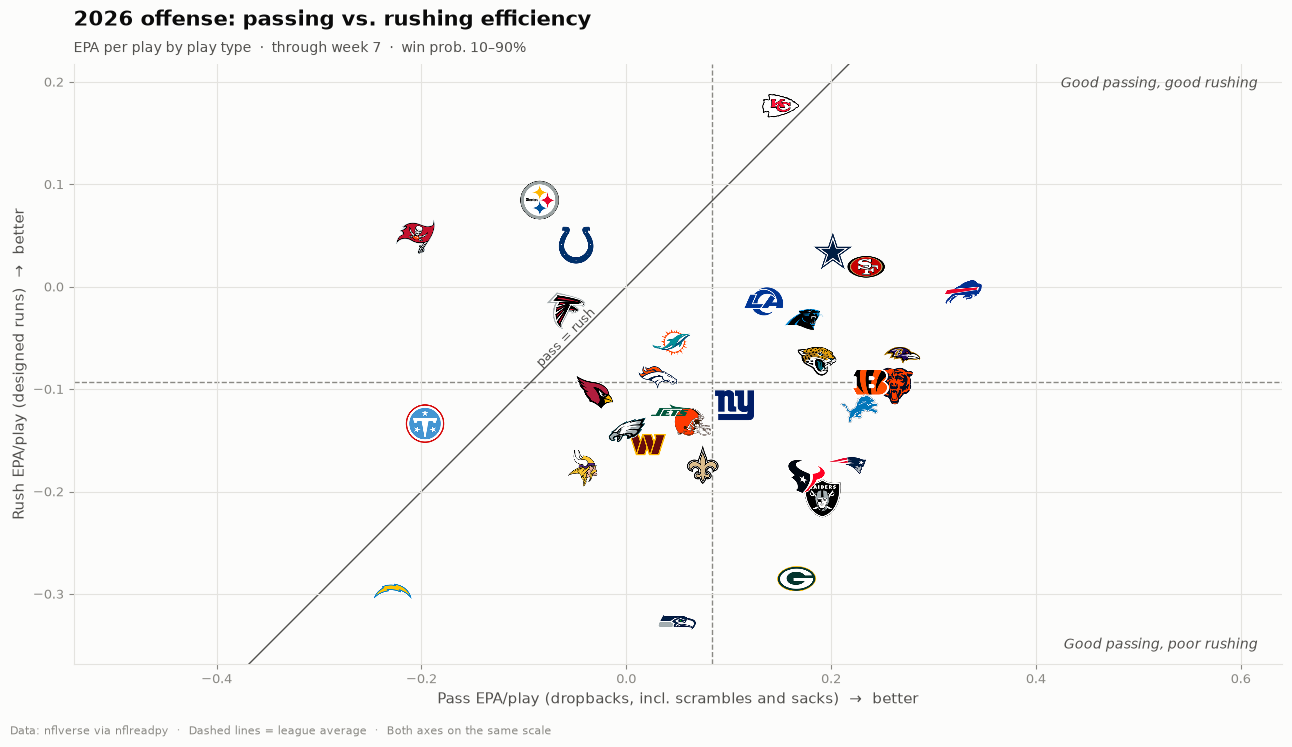

In [6]:
fig, ax = plot_pass_vs_rush(
    split,
    title=f"{SEASON} offense: passing vs. rushing efficiency",
    subtitle=f"EPA per play by play type  ·  {through}  ·  win prob. 10–90%",
)

In [7]:
print("League avg pass EPA/play:", round(split['pass_epa'].mean(), 3))
print("League avg rush EPA/play:", round(split['rush_epa'].mean(), 3))
print("Teams that ran better than they passed:", list(split[split['rush_epa'] > split['pass_epa']].index))
print("Corr(pass rate, pass EPA):", round(split['pass_rate'].corr(split['pass_epa']), 2))

League avg pass EPA/play: 0.084
League avg rush EPA/play: -0.093
Teams that ran better than they passed: ['KC', 'IND', 'ATL', 'PIT', 'TEN', 'TB']
Corr(pass rate, pass EPA): 0.21


## Pass/run tendencies by down
How often each team passes on 1st, 2nd and 3rd down. Raw pass rate mostly reflects situation: everyone passes on 3rd & long or when trailing late. So the color uses **pass rate over expected (PROE)**, the actual pass rate minus nflverse's `xpass` (expected pass probability given down, distance, field position, score and time). That isolates the play-caller's tendency. PROE is then **re-centered on the league average** for each down (in competitive situations the whole league runs slightly more than `xpass` predicts), so 0 = a typical team.

Each cell shows the pass rate, then PROE vs. the league average in percentage points (★ = 95% interval excludes the league average). 4th down is left out (too few go-for-it plays per team).

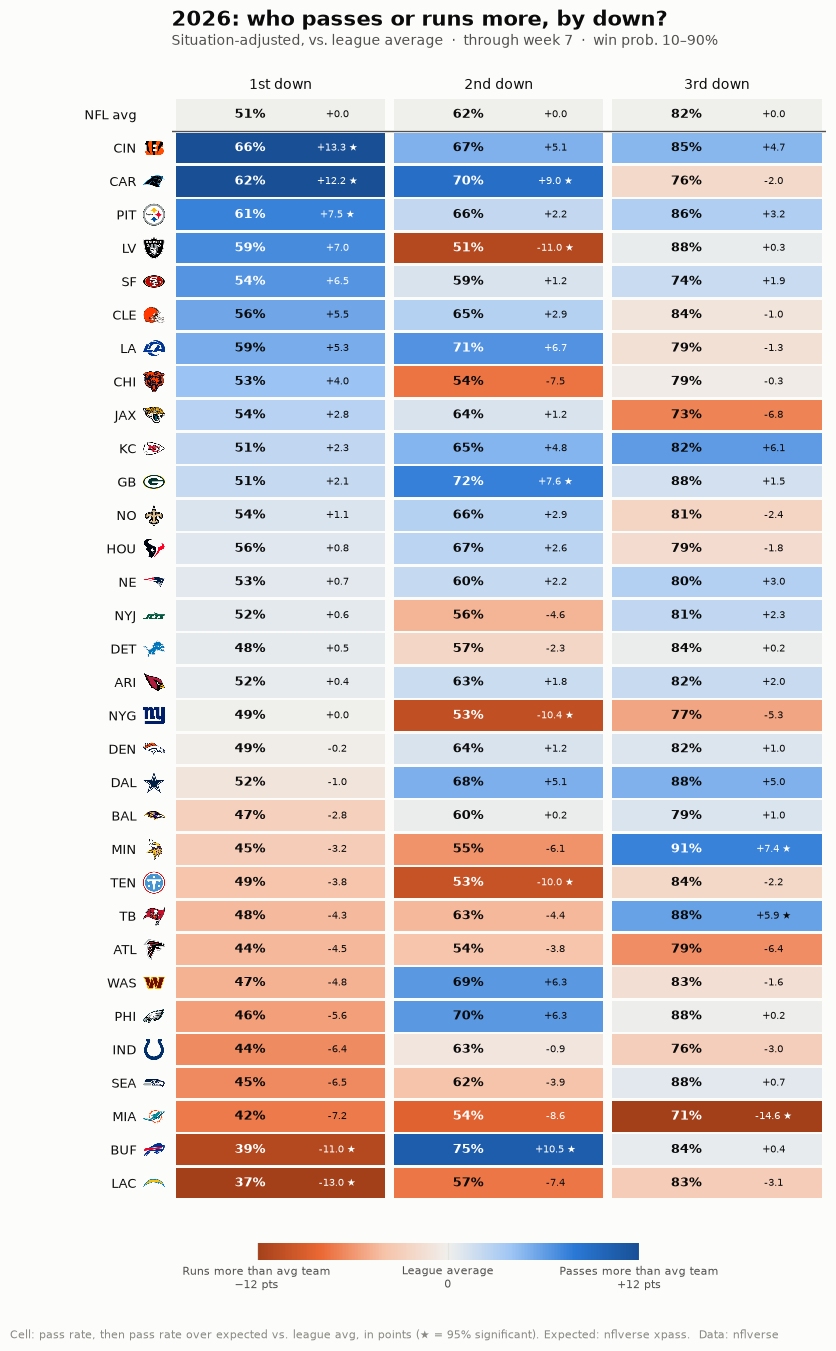

In [8]:
from nfl_analytics import pass_tendency_by_down, plot_pass_tendency_by_down

tendency = pass_tendency_by_down(plays)
fig, ax = plot_pass_tendency_by_down(
    tendency,
    title=f"{SEASON}: who passes or runs more, by down?",
    subtitle=f"Situation-adjusted, vs. league average  ·  {through}  ·  win prob. 10–90%",
)

In [9]:
# Are teams consistent across downs? Correlation of team PROE between downs.
wide = tendency[tendency["team"] != "NFL"].pivot(index="team", columns="situation", values="proe_vs_nfl")
wide.corr().round(2)

situation,1st down,2nd down,3rd down
situation,,,
1st down,1.00,0.24,0.25
2nd down,0.24,1.00,0.28
3rd down,0.25,0.28,1.00


## Ideas to explore next
- Split 1st down by **field position** (own territory vs. red zone). Does running gain ground near the goal line?
- Compare **early-season vs. late-season** efficiency to see who improved.
- Check how well net EPA/play **predicts win totals** (`nflreadpy.load_schedules`).
- Re-run without the garbage-time filter (`offensive_plays(pbp, wp_range=None)`) and see who moves.